In [2]:
import sys
sys.path.append('../../../../backend/db/')
sys.path.append('../../scrapers/')
from rec_sport_scraper import get_url_response
from database import get_db_connection

In [3]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
conn = get_db_connection()
cur = conn.cursor()

In [5]:
def location_id_to_name(data) -> dict:
    """Map top-level LocationId -> LocationName from a JSON string or parsed list."""
    if isinstance(data, str):
        data = json.loads(data)
    return {loc["LocationId"]: loc["LocationName"] for loc in data}

res = get_url_response(2, 2, "https://goboardapi.azurewebsites.net/api/FacilityCount/GetCountsByAccount?AccountAPIKey=8E2C21D2-6F5D-45C1-AF9E-C23AEBFDA68B&ShowSubLocationCount=true")
data = json.loads(res.text)
id_to_name_map = location_id_to_name(data)
print(id_to_name_map)

{6697: 'Maguire Field', 9494: ' LW North', 3367: 'SWRC Weight Room ', 3368: 'SWRC Cardio Room 2', 5844: 'SWRC Cardio Room 1', 3230: 'Multi-Purpose Court 1', 3231: 'Multi-Purpose Court 2', 3232: 'Multi-Purpose Court 3', 3233: 'Multi-Purpose Court 4', 3234: 'Multi-Purpose Court 5', 3235: 'Multi-Purpose Court 6', 3243: 'SWRC Tennis Courts', 3253: 'UVS Sand Volleyball', 3218: 'SRFC Squash', 3219: 'SRFC Table Tennis', 3221: 'Florida Pool', 4647: "O'Connell Center Pool", 3222: 'SRFC Upper Weight Room', 3642: 'SRFC Lower Functional Area', 3214: 'SRFC Multi-purpose Court', 3216: 'SRFC Racquetball'}


In [6]:
def query_to_df(cur, query):
    rows = cur.execute(query).fetchall()
    return pd.DataFrame(rows)

In [7]:
count_per_loc = cur.execute("""
                SELECT "LocationId", COUNT(distinct("LastUpdatedDateAndTime"))
                FROM raw_recsports_data
                GROUP BY "LocationId";
            """).fetchall()


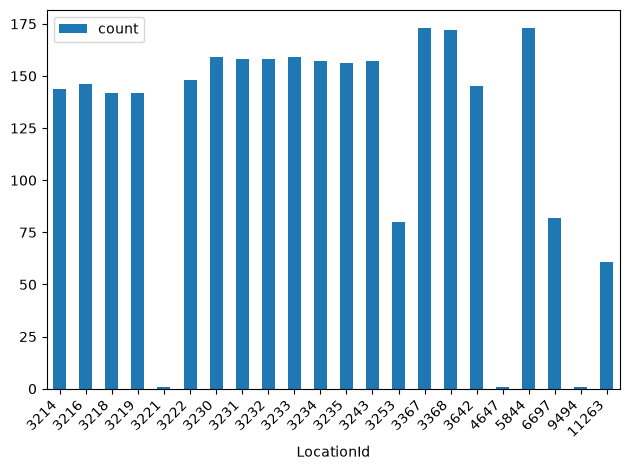

In [8]:
data_per_loc = query_to_df(cur, """
                SELECT "LocationId", COUNT(distinct("LastUpdatedDateAndTime"))
                FROM raw_recsports_data
                GROUP BY "LocationId";
            """)
fig = data_per_loc.plot.bar(x='LocationId', y='count', rot=0)
# fig.set_xticklabels([])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [9]:
data_per_hour = query_to_df(cur, """
                SELECT EXTRACT(HOUR FROM "LastUpdatedDateAndTime") as Hour, COUNT(distinct("LastUpdatedDateAndTime"))
FROM raw_recsports_data
GROUP BY 1;
            """)

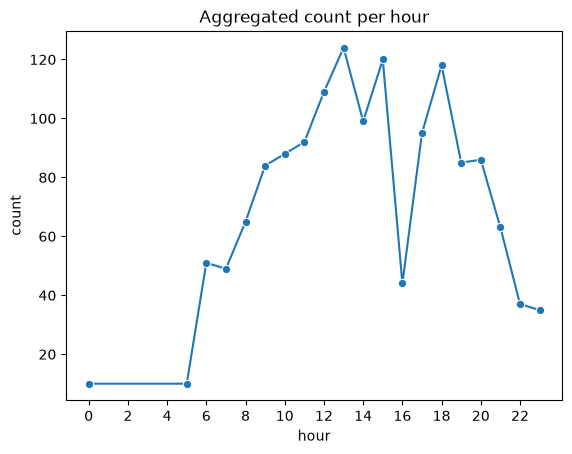

In [10]:

ax = sns.lineplot(data=data_per_hour, x="hour", y="count", marker="o")
ax.set_xticks(range(0, 24, 2))
plt.title("Aggregated count per hour")  # Adds the title
plt.show()


In [11]:
data_per_loc_per_hour = query_to_df(cur, """
                SELECT "LocationId", EXTRACT(HOUR FROM "LastUpdatedDateAndTime") as Hour, COUNT(distinct("LastUpdatedDateAndTime"))
FROM raw_recsports_data
GROUP BY 1, 2;
            """)

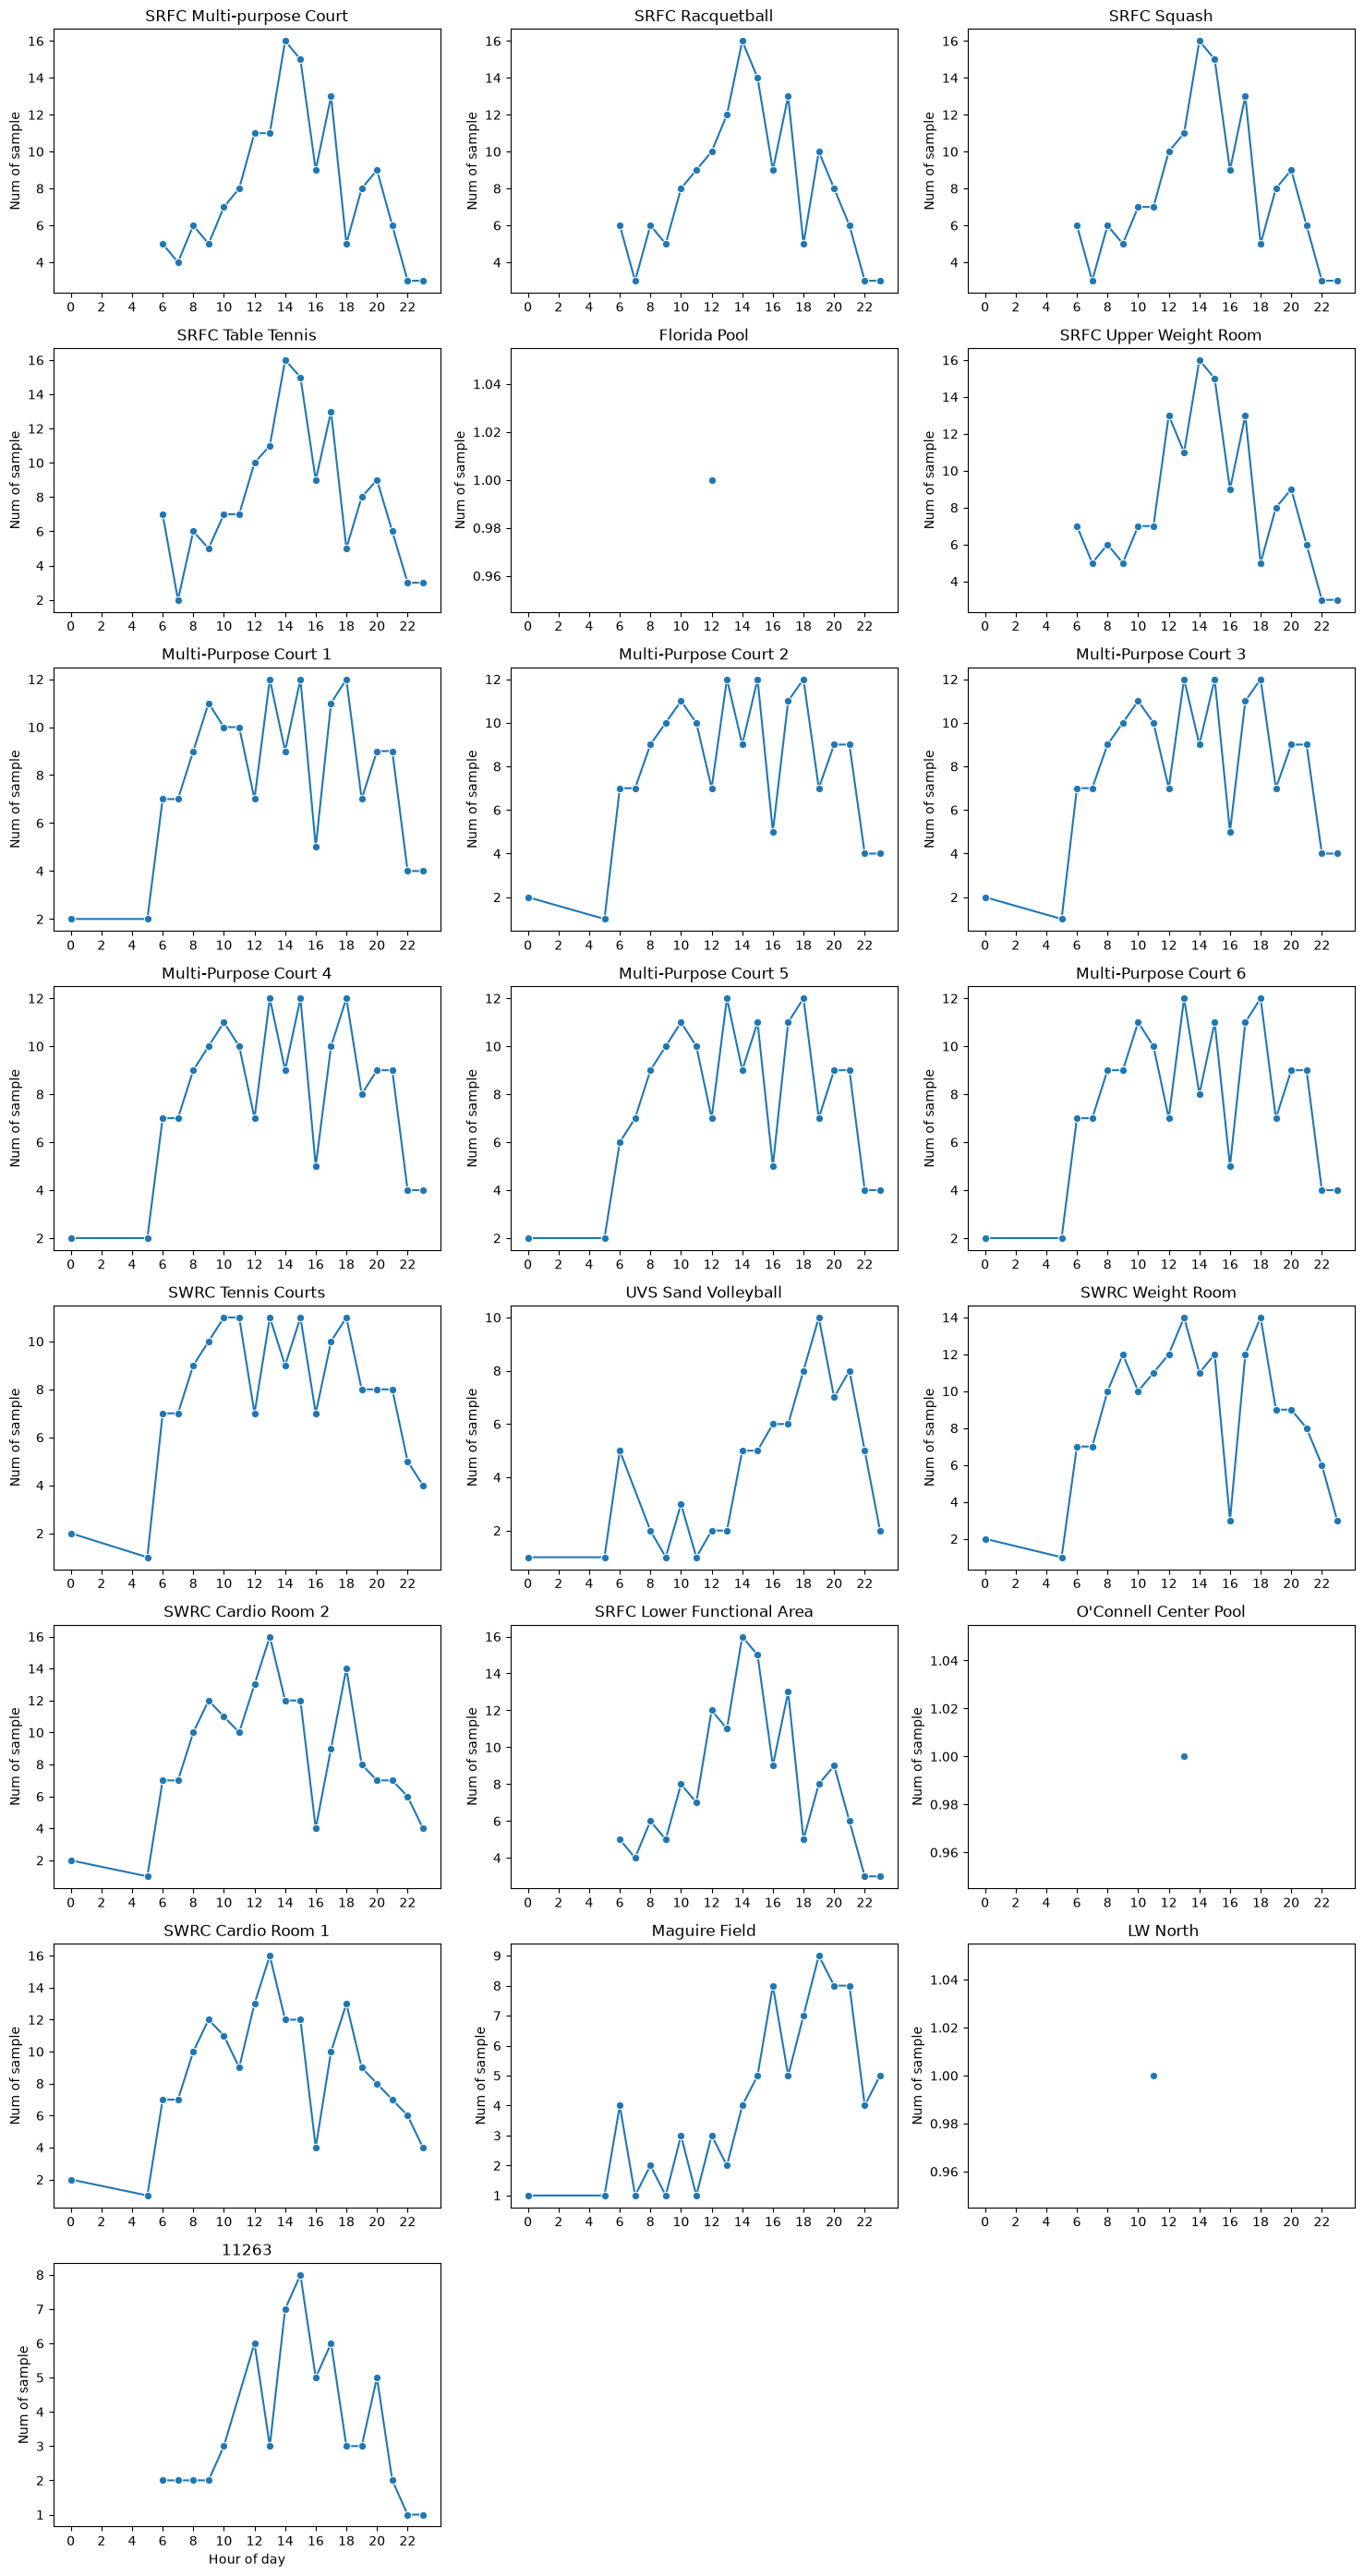

In [12]:
def plot_counts_by_hour(df: pd.DataFrame, id_to_name: dict | None = None, ncols: int = 3):
    """One boxplot panel per LocationId: count distribution for each hour."""
    loc_ids = sorted(df["LocationId"].unique())
    nrows = -(-len(loc_ids) // ncols)  # ceiling division

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows),
                             sharex=True, squeeze=False)
    axes = axes.flatten()

    hours = list(range(int(df["hour"].min()), int(df["hour"].max()) + 1, 2))

    for ax, loc_id in zip(axes, loc_ids):
        sub = df[df["LocationId"] == loc_id]
        sns.lineplot(data=sub, x="hour", y="count", ax=ax, marker="o")
        ax.set_title(str(id_to_name.get(loc_id, loc_id)) if id_to_name else str(loc_id))
        ax.set_xlabel("Hour of day")
        ax.set_ylabel("Num of sample")
        ax.set_xticks(hours)
        ax.tick_params(labelbottom=True)

    # Hide any unused panels
    for ax in axes[len(loc_ids):]:
        ax.set_visible(False)

    fig.tight_layout()
    plt.show()

plot_counts_by_hour(data_per_loc_per_hour, id_to_name=id_to_name_map)   # titles are location names


In [13]:
all_time_counts = query_to_df(cur, """WITH dedup AS (
    SELECT DISTINCT "LocationId", "LastUpdatedDateAndTime", "LastCount"
    FROM raw_recsports_data
)
SELECT *
FROM dedup
WHERE "LocationId" IN (
    SELECT "LocationId" FROM dedup GROUP BY "LocationId" HAVING COUNT(*) > 100
);""")

In [14]:
df = all_time_counts
df["LastUpdatedDateAndTime"] = pd.to_datetime(df["LastUpdatedDateAndTime"])
df["hour"] = df["LastUpdatedDateAndTime"].dt.hour
df["dayofweek"] = df["LastUpdatedDateAndTime"].dt.dayofweek  # 0 = Monday
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

corr_by_loc = (
    df.groupby("LocationId")[["hour", "dayofweek", "LastCount"]]
      .corr(method="spearman")
      .xs("LastCount", level=1)[["hour", "dayofweek"]]
)
print(corr_by_loc)

                hour  dayofweek
LocationId                     
3214        0.592332   0.171022
3216        0.195253  -0.091130
3218        0.155237   0.042592
3219        0.629248   0.086411
3222        0.105950  -0.170026
3230        0.758870   0.116792
3231        0.762143   0.214436
3232        0.750961   0.111703
3233        0.716547   0.186609
3234        0.530454   0.312835
3235        0.536142   0.191446
3243        0.704056   0.317385
3367        0.337927  -0.311267
3368        0.297555  -0.044106
3642        0.239170  -0.198366
5844        0.189827  -0.126585


In [15]:
# Add weekend flag and Spearman (monotonic, not just linear)
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

res = (
    df.groupby("LocationId")[["hour", "is_weekend", "LastCount"]]
      .corr(method="spearman")
      .xs("LastCount", level=1)[["hour", "is_weekend"]]
)
res["n"] = df.groupby("LocationId").size()
print(res.round(2))

            hour  is_weekend    n
LocationId                       
3214        0.59        0.24  144
3216        0.20       -0.09  146
3218        0.16        0.02  142
3219        0.63        0.16  142
3222        0.11       -0.12  148
3230        0.76        0.05  159
3231        0.76        0.16  158
3232        0.75        0.13  158
3233        0.72        0.18  159
3234        0.53        0.20  157
3235        0.54        0.15  156
3243        0.70        0.30  157
3367        0.34       -0.27  173
3368        0.30       -0.11  172
3642        0.24       -0.12  145
5844        0.19       -0.13  173


<Axes: xlabel='hour'>

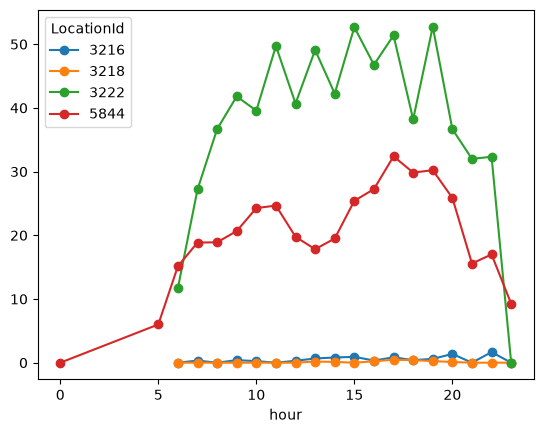

In [16]:
hourly = df.groupby(["LocationId", "hour"])["LastCount"].mean().unstack(0)
hourly[[3216, 3218, 3222, 5844]].plot(marker="o")

In [17]:
id_to_name_map[3367]

'SWRC Weight Room '

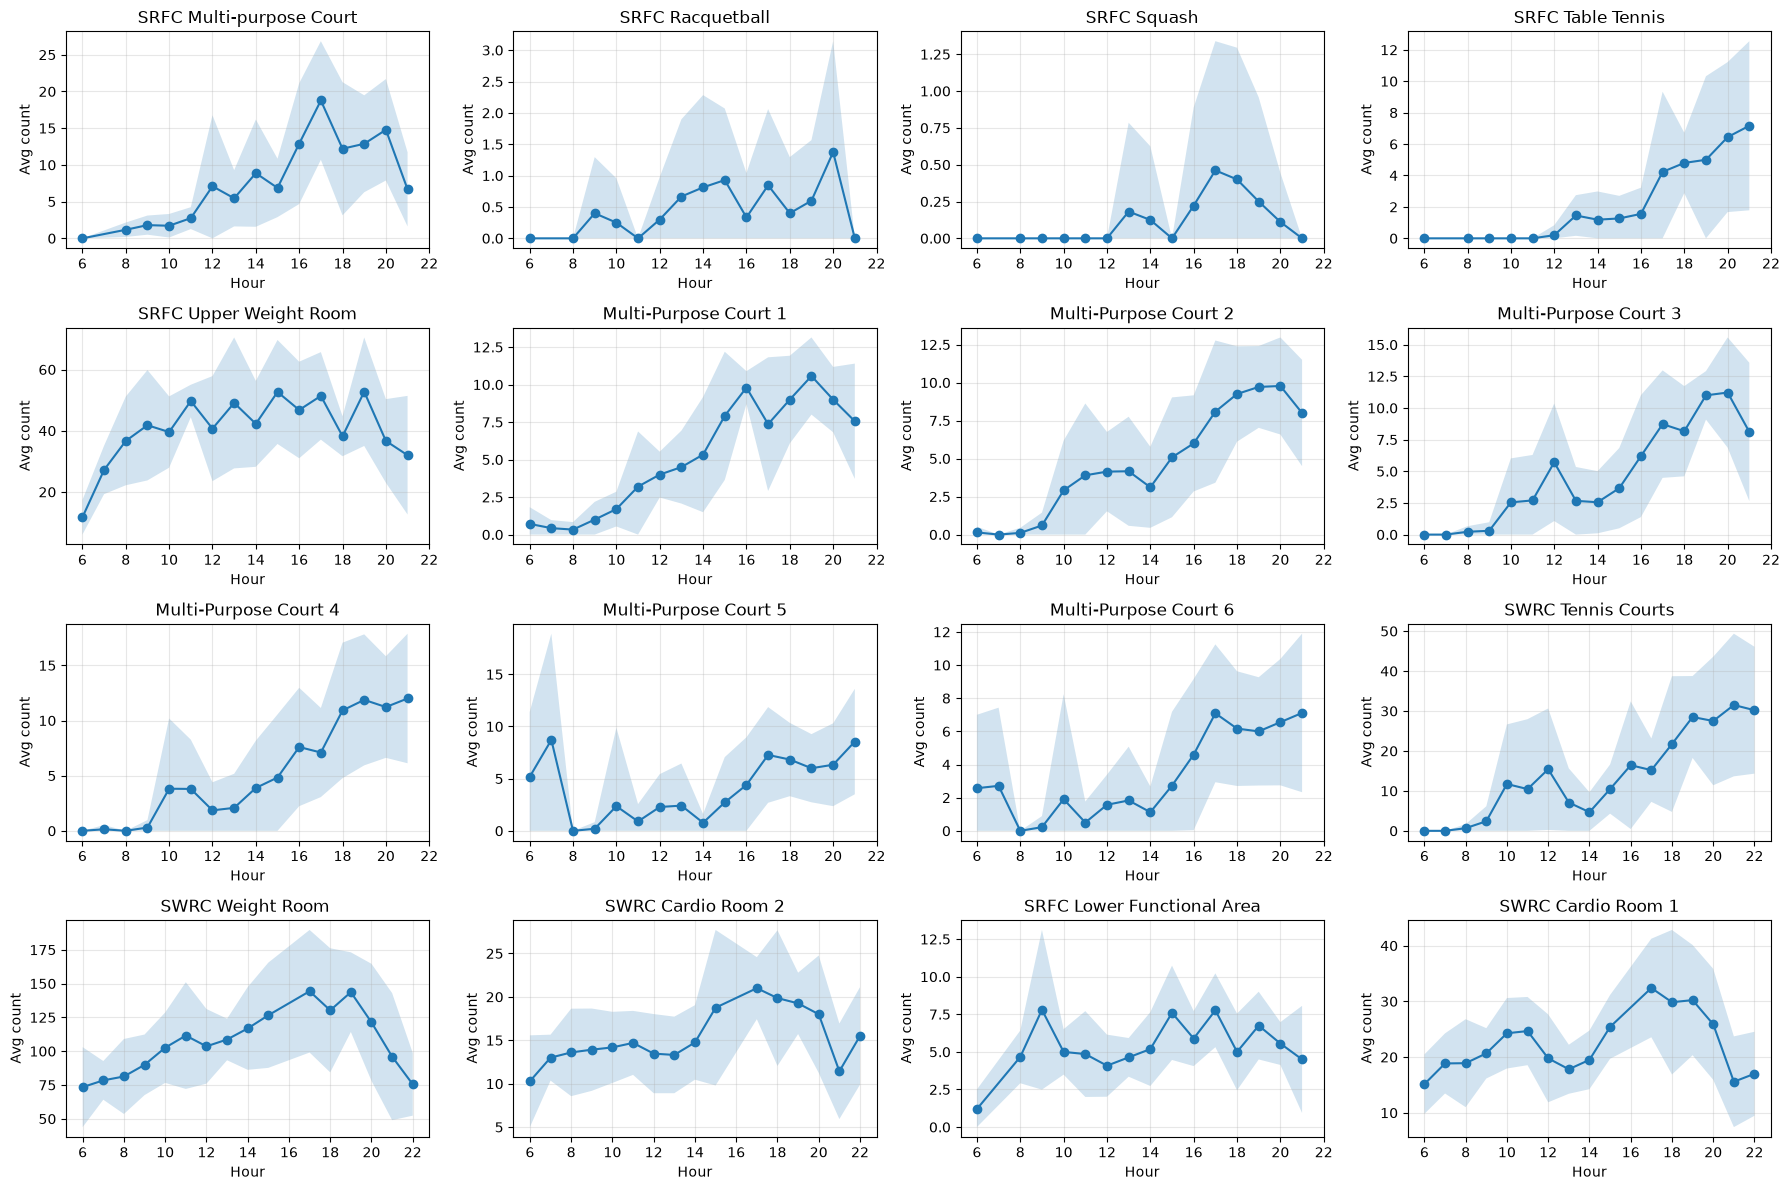

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_avg_count_by_hour(df, id_to_name=None, ncols=4, min_points=5):
    # Mean, spread and sample size per (location, hour)
    stats = (
        df.groupby(["LocationId", "hour"])["LastCount"]
          .agg(mean="mean", std="std", n="size")
          .reset_index()
    )
    stats = stats[stats["n"] >= min_points]  # drop thinly sampled hours

    loc_ids = sorted(stats["LocationId"].unique())
    nrows = -(-len(loc_ids) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3 * nrows),
                             squeeze=False)
    axes = axes.flatten()

    hours = list(range(int(stats["hour"].min()), int(stats["hour"].max()) + 1, 2))

    for ax, loc_id in zip(axes, loc_ids):
        s = stats[stats["LocationId"] == loc_id].sort_values("hour")
        ax.plot(s["hour"], s["mean"], marker="o")
        ax.fill_between(s["hour"],
                        (s["mean"] - s["std"]).clip(lower=0),
                        s["mean"] + s["std"], alpha=0.2)
        ax.set_title(str(id_to_name.get(loc_id, loc_id)) if id_to_name else str(loc_id))
        ax.set_xticks(hours)
        ax.tick_params(labelbottom=True)
        ax.set_xlabel("Hour")
        ax.set_ylabel("Avg count")
        ax.grid(alpha=0.3)

    for ax in axes[len(loc_ids):]:
        ax.set_visible(False)

    fig.tight_layout()
    plt.show()

plot_avg_count_by_hour(df, id_to_name=id_to_name_map)

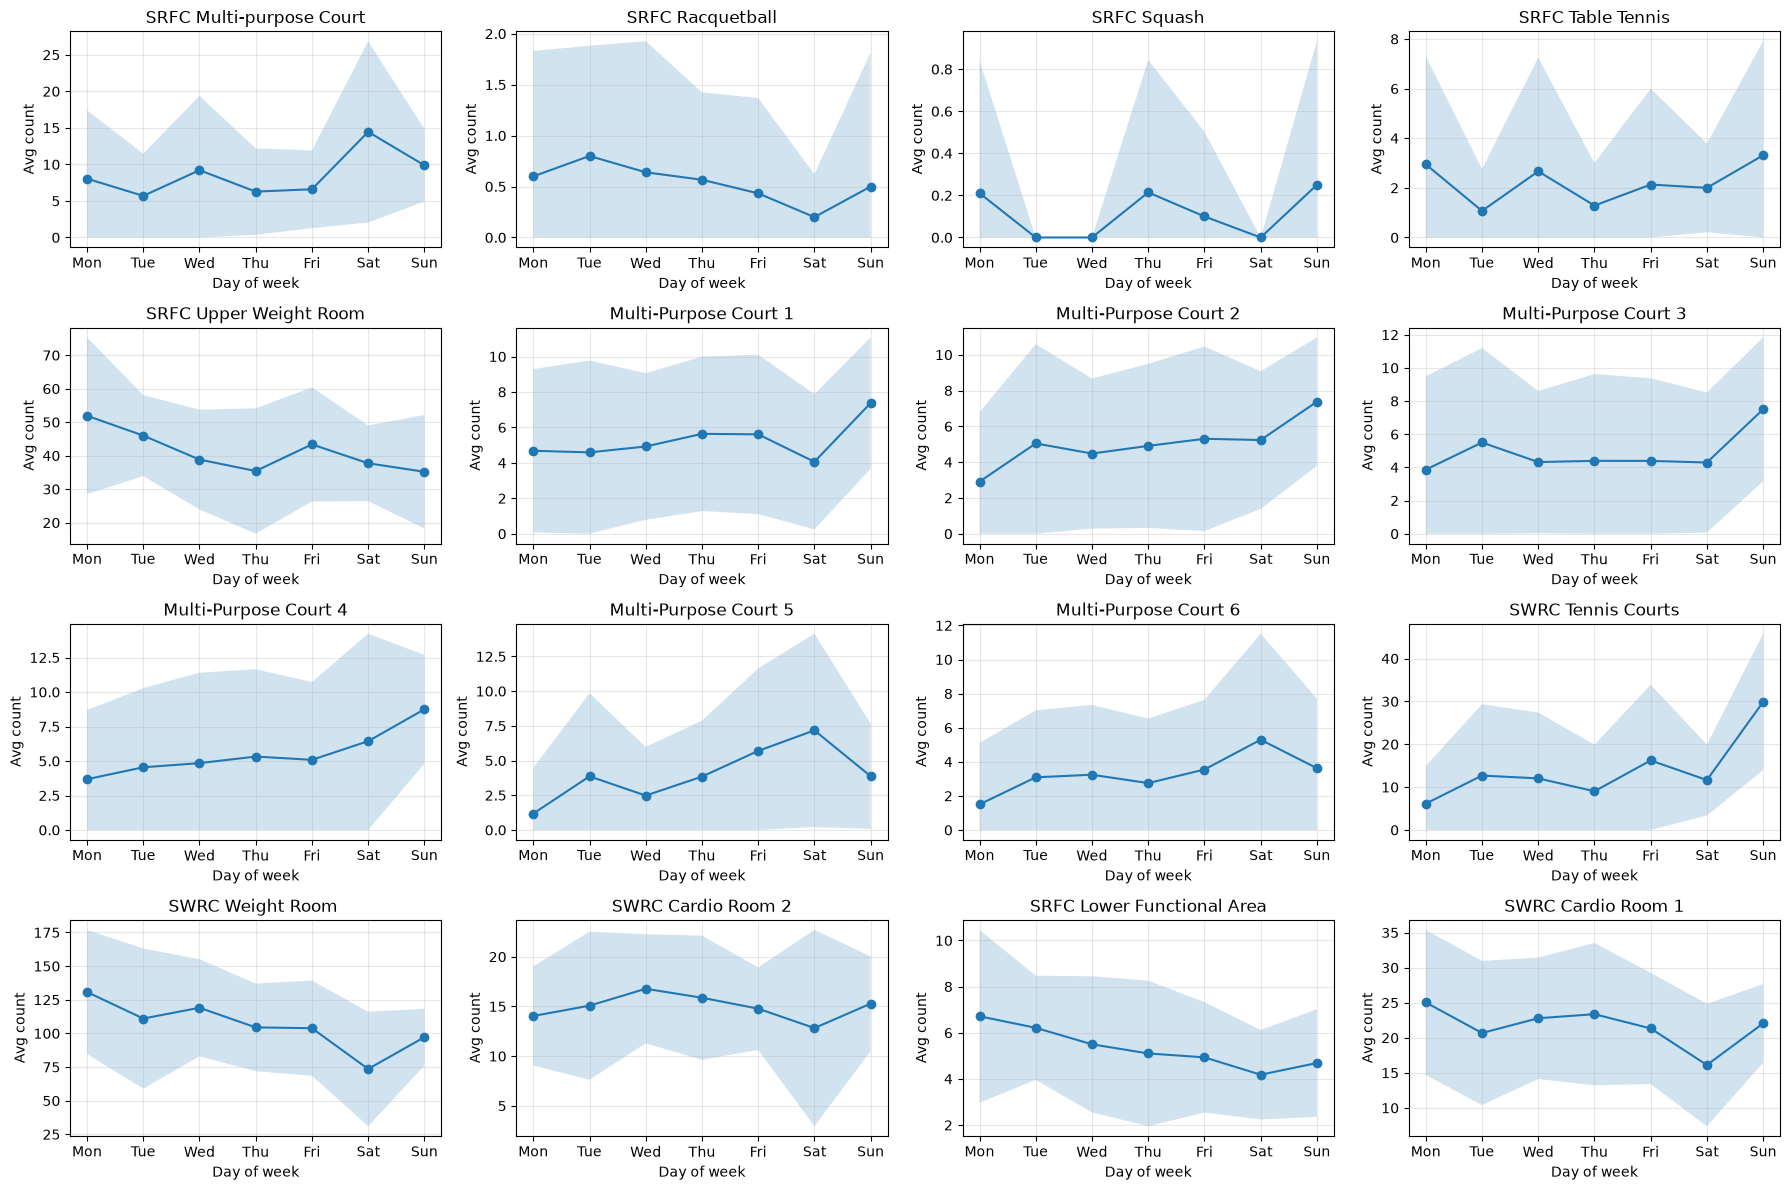

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DAY_LABELS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def plot_avg_count_by_day(df, by="dayofweek", id_to_name=None, ncols=4, min_points=5):
    """
    by="dayofweek": average count for each weekday (Mon..Sun), per location
    by="date":      average count for each calendar date, per location
    """
    df = df.copy()
    ts = pd.to_datetime(df["LastUpdatedDateAndTime"])
    df["dayofweek"] = ts.dt.dayofweek
    df["date"] = ts.dt.normalize()   # midnight timestamp, keeps date axis formatting

    stats = (
        df.groupby(["LocationId", by])["LastCount"]
          .agg(mean="mean", std="std", n="size")
          .reset_index()
    )
    stats = stats[stats["n"] >= min_points]  # drop thinly sampled days

    loc_ids = sorted(stats["LocationId"].unique())
    nrows = -(-len(loc_ids) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3 * nrows),
                             squeeze=False)
    axes = axes.flatten()

    for ax, loc_id in zip(axes, loc_ids):
        s = stats[stats["LocationId"] == loc_id].sort_values(by)
        ax.plot(s[by], s["mean"], marker="o")
        ax.fill_between(s[by],
                        (s["mean"] - s["std"]).clip(lower=0),
                        s["mean"] + s["std"], alpha=0.2)
        ax.set_title(str(id_to_name.get(loc_id, loc_id)) if id_to_name else str(loc_id))
        ax.set_ylabel("Avg count")
        ax.grid(alpha=0.3)

        if by == "dayofweek":
            ax.set_xticks(range(7))
            ax.set_xticklabels(DAY_LABELS)
            ax.set_xlabel("Day of week")
        else:
            ax.tick_params(axis="x", labelrotation=45)
            ax.set_xlabel("Date")

    for ax in axes[len(loc_ids):]:
        ax.set_visible(False)

    fig.tight_layout()
    plt.show()

# Usage
plot_avg_count_by_day(df, by="dayofweek", id_to_name=id_to_name_map)


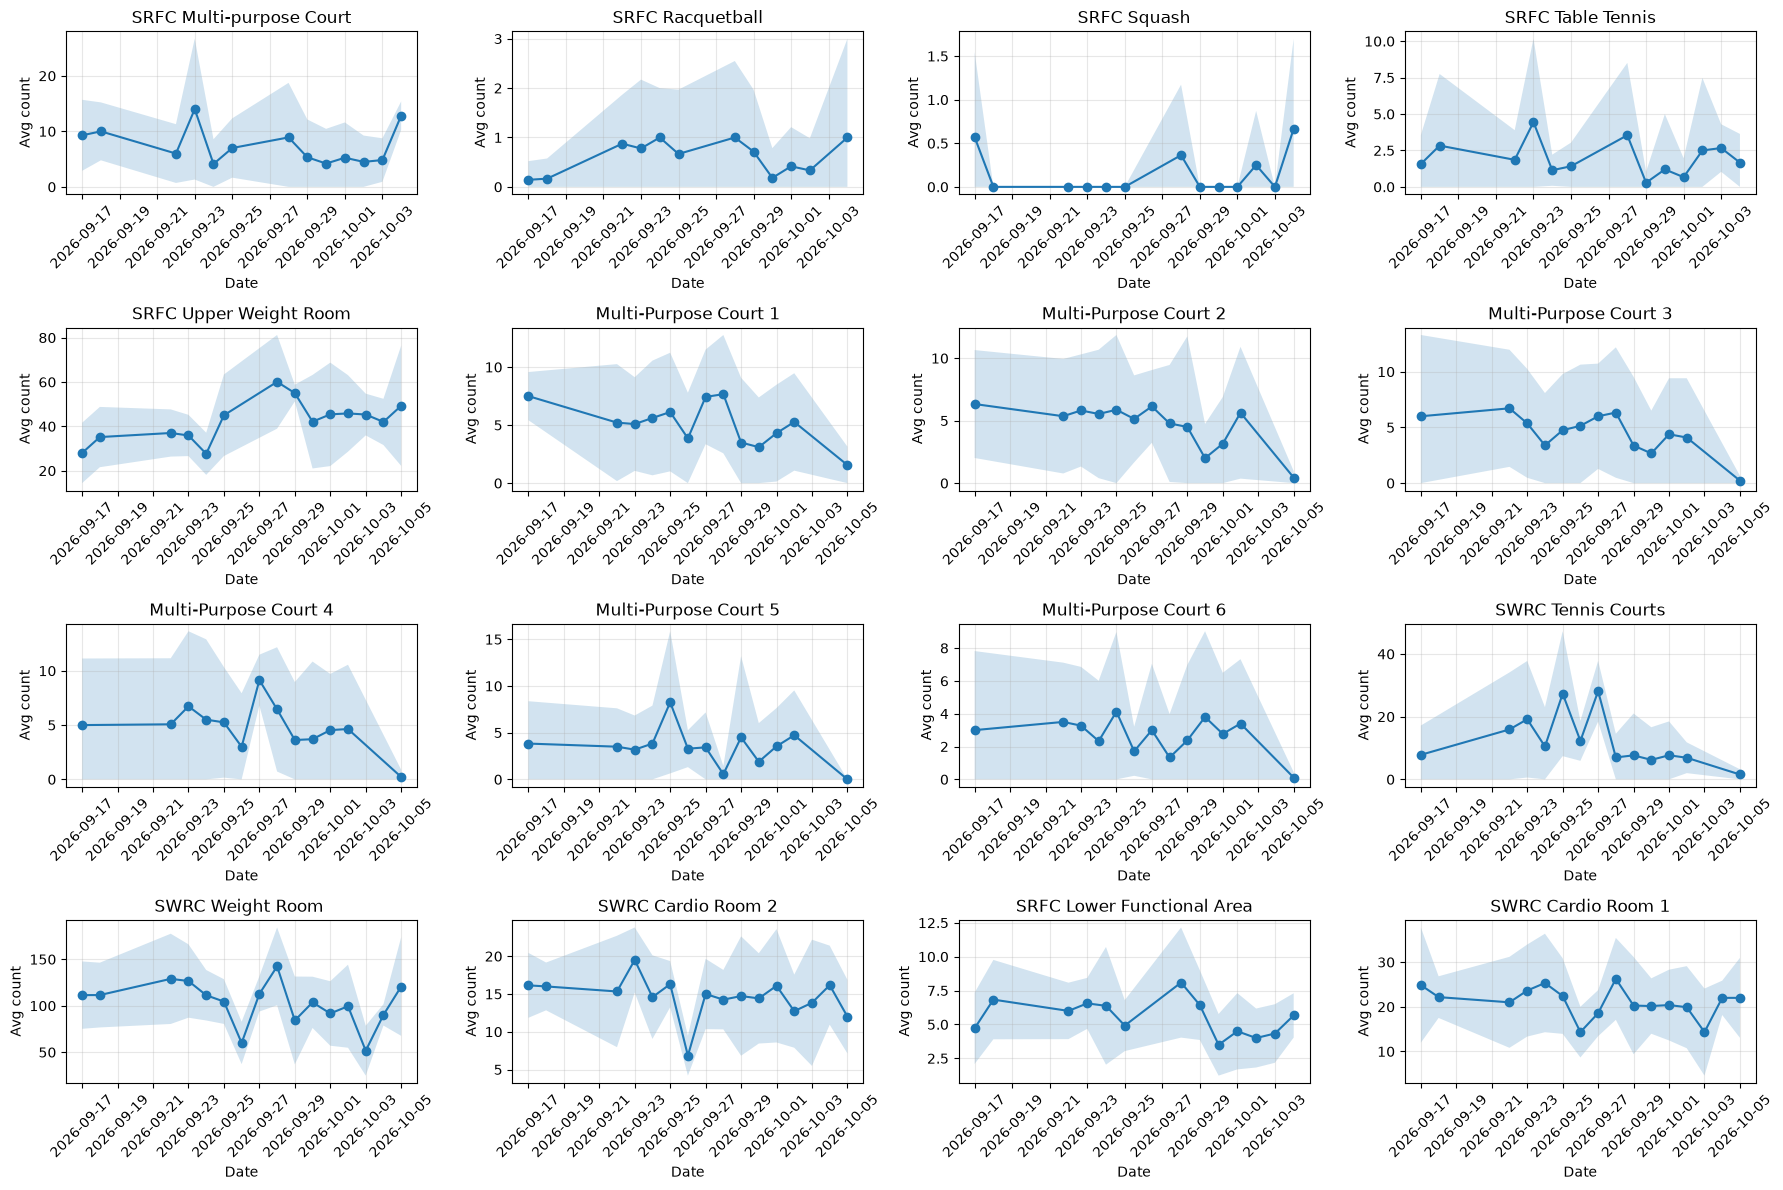

In [25]:
plot_avg_count_by_day(df, by="date", id_to_name=id_to_name_map, min_points=6)

In [24]:
ts = pd.to_datetime(df["LastUpdatedDateAndTime"])
per_day = df.groupby(["LocationId", ts.dt.normalize()]).size()
print(per_day.describe())

count    346.000000
mean       7.193642
std        3.473304
min        1.000000
25%        5.000000
50%        7.000000
75%       10.000000
max       15.000000
dtype: float64


In [92]:
from sklearn.cluster import KMeans

hourly = df.groupby(["LocationId", "hour"])["LastCount"].mean().unstack("hour").fillna(0)
norm = hourly.div(hourly.max(axis=1), axis=0)

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(norm)
norm["cluster"] = km.labels_
print(norm["cluster"].sort_values())

LocationId
3222    0
3368    0
3642    0
5844    0
3367    0
3214    1
3218    1
3216    1
3235    1
3234    1
3219    1
3230    2
3232    2
3231    2
3243    2
3233    2
Name: cluster, dtype: int32
